# Space-time spectrum of PIV divergence, and gravity-wave phase speeds

Input: a 3-month, half-hourly divergence field on a lat/lon grid, with cloud gaps (NaNs).

Output: a normalized (wavenumber, frequency) variance-density anomaly plot with lines of
constant phase speed, plus a quantitative estimate of the dominant phase speed.

Everything is done step by step on plain numpy arrays. Only tiny helper functions are
defined; all the real logic sits in flat, commented cells so you can inspect intermediate
variables at any point.

**Read the "resolution reality check" cell (Step 3) before interpreting anything.**

## Step 0 — Imports

In [1]:
import numpy as np
import xarray as xr
import pandas as pd
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter1d, gaussian_filter
from matplotlib.colors import BoundaryNorm

np.seterr(divide='ignore', invalid='ignore')   # we divide by weights that can be zero
plt.rcParams['figure.dpi'] = 110

## Step 1 — Load the 3-month divergence file

Only two things matter here: the array must end up with dimension order
`(time, latitude, longitude)`, and latitude/longitude must be **ascending** so that
+y means north and +x means east. If latitude is stored descending (common in satellite
products) the sort below fixes it, and without that fix every wave direction you infer
later would be flipped north-south.

In [2]:
DIVFILE = '~/Box/GWaves_2023_10_11-14_SEPAC/PIV_outputs/Hanna_outputs/uv_div_2023-09-01_to_2023-11-30_window_size-40_overlap-30_maxwind-20mps_u_threshold-3mps_v_threshold-3mps_cloud_temp_mask-on_temp_threshold-273K_snr-1p2_u_sign-negative_v_sign-positive.nc'
ds = xr.open_dataset(DIVFILE)
display(ds)

<xarray.Dataset> Size: 998MB
Dimensions:     (time: 4277, lat: 120, lon: 162)
Coordinates:
  * lat         (lat) float32 480B -34.26 -33.89 -33.53 ... 8.314 8.678 9.042
  * lon         (lon) float32 648B -129.3 -128.9 -128.5 ... -71.43 -71.07 -70.7
  * time        (time) datetime64[ns] 34kB 2023-09-01 ... 2023-11-30T23:00:00
Data variables:
    u2          (time, lat, lon) float32 333MB ...
    v2          (time, lat, lon) float32 333MB ...
    divergence  (time, lat, lon) float32 333MB ...
Attributes:
    window_size:       40
    overlap:           30
    search_area_size:  40
    dt_seconds:        1800.0
    source:            OpenPIV extended_search_area_piv
    valid_fraction:    0.34002057613168724

In [5]:
ds.lat.diff('lat').mean()

<xarray.DataArray 'lat' ()> Size: 8B
array(0.36385688)

In [40]:
### Just masked divergence file, no u2 v2 ###########
# DIVFILE = '~/Box/GWaves_2023_10_11-14_SEPAC/PIV_outputs/Hanna_outputs/div_2023_sep-nov_combined.nc'

### UNmasked divergence file, u2 v2 included ###########
#DIVFILE = '~/Box/GWaves_2023_10_11-14_SEPAC/PIV_outputs/Hanna_outputs/uv_div_2023-09-01_to_2023-11-30_window_size-40_overlap-30_maxwind-20mps_u_threshold-3mps_v_threshold-3mps_cloud_temp_mask-off_snr-1p2_u_sign-none_v_sign-none.nc'

### Masked divergence file, u2 v2 included ###########
DIVFILE = '~/Box/GWaves_2023_10_11-14_SEPAC/PIV_outputs/Hanna_outputs/uv_div_2023-09-01_to_2023-11-30_window_size-40_overlap-30_maxwind-20mps_u_threshold-3mps_v_threshold-3mps_cloud_temp_mask-on_temp_threshold-273K_snr-1p2_u_sign-negative_v_sign-positive.nc'

DIVVAR = 'divergence'      # name of the divergence variable inside the file
LAT, LON, TIME = 'lat', 'lon', 'time'

ds = xr.open_dataset(DIVFILE)


# Sort all three axes so signs and time steps are unambiguous
ds = ds.sortby(TIME).sortby(LAT).sortby(LON)

# Force dimension order to (time, lat, lon) - every cell below assumes this
div = ds[DIVVAR].transpose(TIME, LAT, LON)

print('\ndivergence shape (time, lat, lon):', div.shape)


divergence shape (time, lat, lon): (4277, 120, 162)


In [41]:
div

<xarray.DataArray 'divergence' (time: 4277, lat: 120, lon: 162)> Size: 333MB
[83144880 values with dtype=float32]
Coordinates:
  * time     (time) datetime64[ns] 34kB 2023-09-01 ... 2023-11-30T23:00:00
  * lat      (lat) float32 480B -34.26 -33.89 -33.53 ... 8.314 8.678 9.042
  * lon      (lon) float32 648B -129.3 -128.9 -128.5 ... -71.43 -71.07 -70.7
Attributes:
    long_name:  Divergence
    units:      s-1

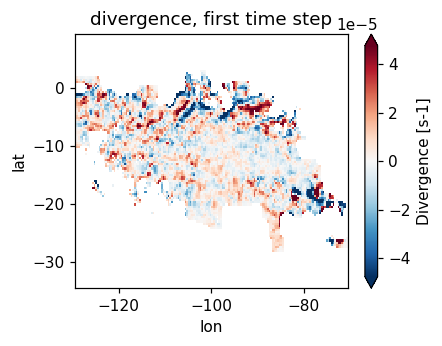

In [44]:
# Quick look: one snapshot, so you know the field is what you think it is.
div.isel(time=0).plot(size=3, cmap='RdBu_r', robust=True)
plt.title('divergence, first time step');

## Step 2 — Convert the lat/lon grid to kilometres

Wavenumbers have to be in physical units or the wavenumber axis is smeared across the
domain by the varying cos(latitude) factor, which broadens a narrow spectral ridge.
Using cos at the band centre is fine as long as the band is not too tall; the printout
below tells you how much cos(lat) actually varies across your domain.

In [8]:
lat = div[LAT].values.astype(float)
lon = div[LON].values.astype(float)
time = div[TIME].values

DEG_KM = 111.32                 # km per degree of latitude
lat0 = float(np.mean(lat))      # reference latitude for the cos factor

dy_km = abs(np.mean(np.diff(lat))) * DEG_KM
dx_km = abs(np.mean(np.diff(lon))) * DEG_KM * np.cos(np.radians(lat0))

# Time step in hours (median is safer than mean if there are missing files)
dt_sec = float(np.median(np.diff(time).astype('timedelta64[s]').astype(float)))
dt_hr = dt_sec / 3600.0

# How much does the cos(lat) approximation cost across the domain?
cos_spread = 100 * (np.cos(np.radians(lat.min())) - np.cos(np.radians(lat.max()))) \
                 / np.cos(np.radians(lat0))

print(f'grid spacing   dx = {dx_km:8.2f} km   dy = {dy_km:8.2f} km')
print(f'time step      dt = {dt_hr:8.3f} h   ({dt_sec:.0f} s)')
print(f'domain         {div.shape[2]} x {div.shape[1]} points, {div.shape[0]} times')
print(f'cos(lat) varies by {abs(cos_spread):.1f}% across the domain '
      '(under ~10% is fine; above that, subset to a narrower latitude band)')

grid spacing   dx =    39.52 km   dy =    40.50 km
time step      dt =    0.500 h   (1800 s)
domain         162 x 120 points, 4277 times
cos(lat) varies by 16.5% across the domain (under ~10% is fine; above that, subset to a narrower latitude band)


## Step 3 — Resolution reality check

Your divergence lives on the **PIV output grid**, not the original image grid. Two
separate limits apply, and they are not the same number:

1. **Nyquist**, set by the PIV grid spacing: nothing shorter than `2*dx` exists at all.
2. **PIV window roll-off**, set by the interrogation window: waves shorter than roughly
   the window are attenuated toward zero amplitude by the cross-correlation itself,
   *before* the divergence is taken. Power there is suppressed, not absent, so it looks
   like a real (but wrong) spectral shape.

Set `PIV_WINDOW_KM` from the run that produced this file (`window_size` in pixels times
the original image pixel size). These two numbers get drawn on the final plot so you
never over-read a feature that is really an artifact of the retrieval.

In [9]:
# ---- from the PIV run that made this file -----------------------------------
PIV_WINDOW_PX  = 40    # window_size
PIV_OVERLAP_PX = 30    # overlap
# search_size doesn't appear: it only sets how far PIV hunts for a match,
# and doesn't change the output grid or the effective smoothing.

PIV_STEP_PX   = PIV_WINDOW_PX - PIV_OVERLAP_PX          # = 10 px
PIV_WINDOW_KM = max(dx_km, dy_km) * PIV_WINDOW_PX / PIV_STEP_PX

lam_nyq = 2 * max(dx_km, dy_km)      # shortest wavelength that exists on this grid
T_nyq = 2 * dt_hr                    # shortest period that exists at this dt

print(f'Nyquist wavelength      {lam_nyq:7.1f} km   <- hard limit, nothing below this')
print(f'PIV window (roll-off)   {PIV_WINDOW_KM:7.1f} km   <- amplitudes suppressed below this')
print(f'Nyquist period          {T_nyq:7.2f} h')
print()
print('Trustworthy wavelength band: roughly '
      f'{PIV_WINDOW_KM:.0f} - {min(len(lon)*dx_km, len(lat)*dy_km):.0f} km')
# print()
# # Aliasing: a wave is safely resolved in time only if its period exceeds 2*dt,
# # i.e. c < lambda / (2*dt). Print that ceiling at a few wavelengths.
# for lam in [100, 200, 500, 1000]:
#     c_max = lam / (2 * dt_hr) / 3.6      # km/h -> m/s
#     print(f'  at lambda = {lam:5d} km, speeds above {c_max:6.1f} m/s alias')

Nyquist wavelength         81.0 km   <- hard limit, nothing below this
PIV window (roll-off)     162.0 km   <- amplitudes suppressed below this
Nyquist period             1.00 h

Trustworthy wavelength band: roughly 162 - 4861 km


## Step 4 — Build the validity mask and look at Divergence coverage

`valid` is the single most important auxiliary array in this whole notebook. Zero-filling
gaps convolves the true spectrum with the spectrum of this mask, so the mask's own
structure sets the floor on how narrow a ridge you can measure.

`TREAT_FILLED_AS_GAP` is a real choice, not a formality. `filters.replace_outliers` with
`method='localmean'` invents smooth structure at exactly the scales you are measuring.
Run the whole notebook both ways. If the answer moves, believe the `True` version.

In [10]:
TREAT_FILLED_AS_GAP = True     # treat replace_outliers fills as missing, not as data

D = div.values.astype(np.float64)      # (nt, ny, nx) working array
valid = np.isfinite(D)

# If the PIV step stored which vectors were replaced, optionally drop those too
if TREAT_FILLED_AS_GAP and 'invalid_mask' in ds:
    filled = ds['invalid_mask'].transpose(TIME, LAT, LON).values.astype(bool)
    valid &= ~filled
    print('dropped replace_outliers fills:', filled.mean().round(4), 'of all points')

D[~valid] = np.nan                     # keep NaN and valid consistent with each other

coverage = valid.mean(axis=(1, 2))     # fraction of good points per time step
print(f'mean coverage {coverage.mean():.3f}, '
      f'worst {coverage.min():.3f}, best {coverage.max():.3f}')

mean coverage 0.420, worst 0.000, best 0.574


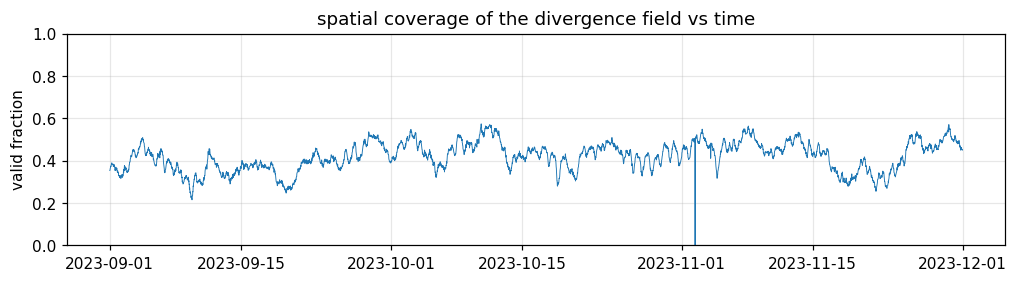

In [11]:
# Coverage through time. Look for long dead stretches - those decide where tiles can go.
fig, ax = plt.subplots(figsize=(11, 2.5))
ax.plot(time, coverage, lw=0.6)
ax.set_ylabel('valid fraction'); ax.set_ylim(0, 1)
ax.set_title('spatial coverage of the divergence field vs time')
ax.grid(alpha=0.3);

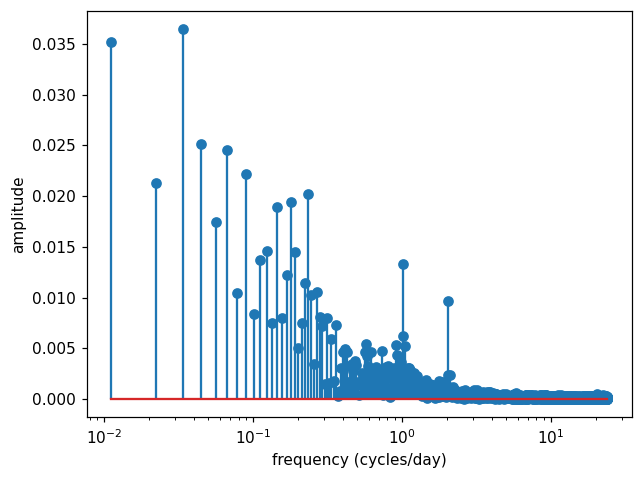

In [60]:
# 1D FFT Of Divergence Coverage --> can see some periodicity of high clouds (limiting coverage)

# STEM PLOTS ARE GOOD< these are discrete estimates,not points to be connected with (fictional) lines.

y = np.asarray(coverage, dtype=float).copy()
t = np.asarray(time, dtype='datetime64[ns]')

dt = (t[1] - t[0]) / np.timedelta64(1, 'D')   # sample spacing in days
N = len(y)

y[y < 0.1] = np.nan                  # mark the dropout
y = y - np.nanmean(y)                # remove the mean
y[np.isnan(y)] = 0                   # dropout now sits at the mean

Y = np.fft.fft(y)
f = np.fft.fftfreq(N, d=dt)          # cycles per day

pos = f > 0                          # keep positive frequencies only
amp = 2 * np.abs(Y[pos]) / N         # amplitude in coverage units

plt.stem(f[pos], amp)
plt.semilogx()
plt.xlabel('frequency (cycles/day)')
plt.ylabel('amplitude');

(0.004526256945438466, 0.004526256945438466)

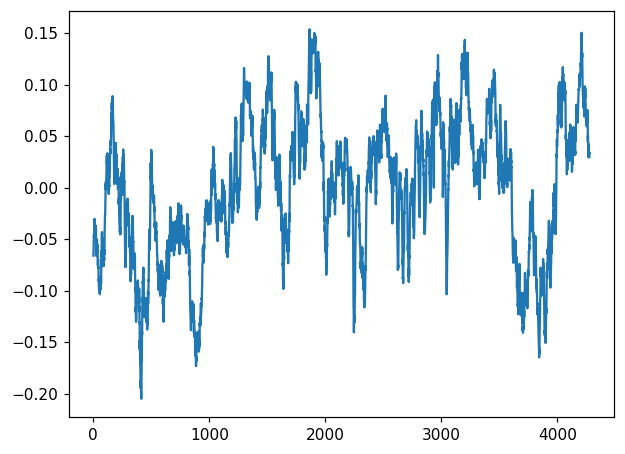

In [61]:
# Total variance 0.0045 (squared fractional cover units) 
plt.plot(y); 
np.var(y), np.std(y)**2

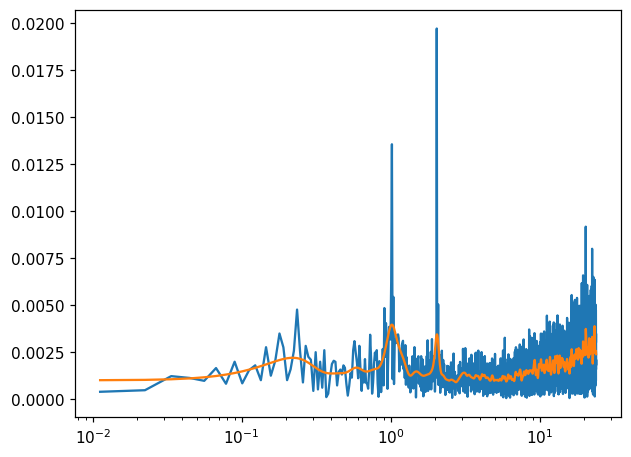

In [63]:
# Here is the variance-preserving "area under the curve" plot: frequency*power by log-frequency

plt.plot(f[pos], f[pos]*amp)
plt.semilogx()

# Now sommthing and lineplots makes sense: area under curve is preserved 
plt.plot(f[pos], gaussian_filter( f[pos]*amp, sigma=5) );



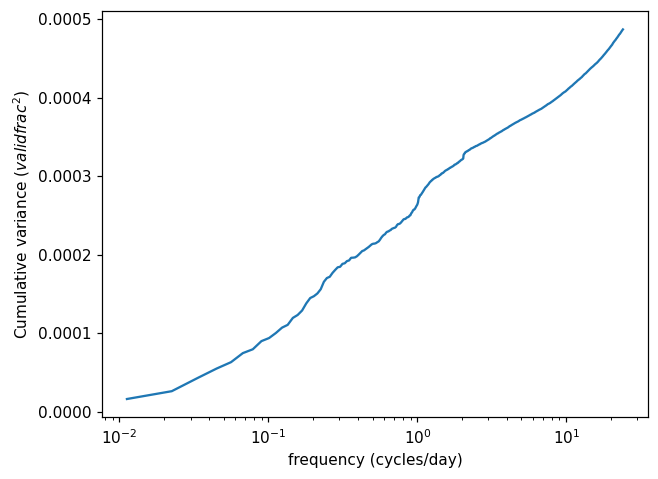

In [64]:
# Variance check: cumulative sum should approach total variance (0.0045)
# Indefinite integral of the the curve above

plt.plot(f[pos], np.cumsum((amp/N)*2))
plt.semilogx()
plt.xlabel('frequency (cycles/day)')
plt.ylabel('Cumulative variance ($validfrac^2$)');

## Step 5 — Mean wind per time step



domain-mean wind speed: 7.2 m/s (range 4.1 - 12.6)


Text(0.5, 1.0, 'domain-mean PIV wind vs time')

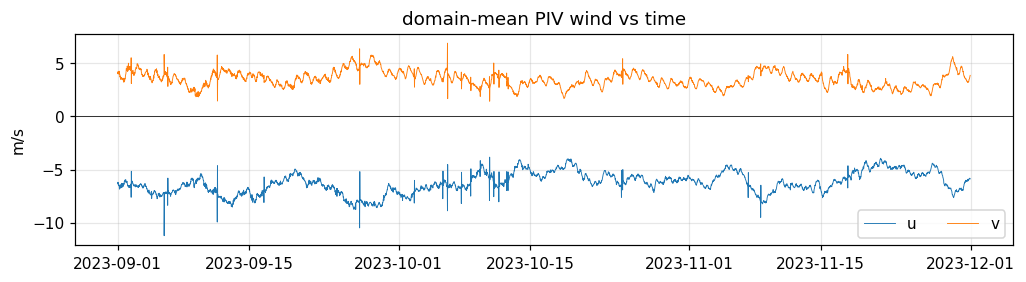

In [10]:
Umean = ds['u2'].transpose(TIME, LAT, LON).mean(dim=(LAT, LON), skipna=True).values
Vmean = ds['v2'].transpose(TIME, LAT, LON).mean(dim=(LAT, LON), skipna=True).values
speed_mean = np.hypot(Umean, Vmean)
print(f'domain-mean wind speed: {np.nanmean(speed_mean):.1f} m/s '
      f'(range {np.nanmin(speed_mean):.1f} - {np.nanmax(speed_mean):.1f})')

fig, ax = plt.subplots(figsize=(11, 2.5))
ax.plot(time, Umean, lw=0.6, label='u')
ax.plot(time, Vmean, lw=0.6, label='v')
ax.axhline(0, color='k', lw=0.5)
ax.set_ylabel('m/s'); ax.legend(ncol=2); ax.grid(alpha=0.3)
ax.set_title('domain-mean PIV wind vs time')

## Step 6 — Create Energy Spectrum



In [11]:
# # %%
# # Normalized wavelength-period spectrum of divergence, with inertia-gravity wave dispersion curves.
# # Paste after your Step 4 cell. Uses: D (nt, ny, nx) with NaN gaps, dx_km, dy_km, dt_hr, lat0, PIV_WINDOW_KM
# import warnings
# import numpy as np
# import matplotlib.pyplot as plt
# from matplotlib.colors import ListedColormap, BoundaryNorm
# from scipy.ndimage import gaussian_filter

# warnings.filterwarnings('ignore', category=RuntimeWarning)   # nanmean of all-NaN snapshots

# SEG_DAYS     = 15              # FFT segment length (50% overlap). Longest resolvable period ~ SEG_DAYS
# MAX_PERIOD_H = 5 * 24          # top of the plot
# N_BINS_F     = 40              # log-spaced frequency bins
# N_BINS_K     = 30              # log-spaced |k| bins
# SMOOTH       = 1               # gaussian smoothing in bins (0 = off)
# N_BV         = 0.01            # buoyancy frequency for the dispersion curves [1/s]
# LAMBDA_Z_KM  = [2, 5, 10, 30]  # vertical wavelengths to draw

# # %%
# # Spectral coordinates and bins
# nt, ny, nx = D.shape
# nseg = int(round(SEG_DAYS * 24 / dt_hr))

# f  = np.fft.fftfreq(nseg, d=dt_hr)                    # cycles/h
# ky = np.fft.fftfreq(ny, d=dy_km)                      # cycles/km
# kx = np.fft.fftfreq(nx, d=dx_km)
# K  = np.sqrt(ky[:, None]**2 + kx[None, :]**2).ravel() # |k|, flattened (ny*nx)

# f_edges = np.geomspace(1 / MAX_PERIOD_H, 1 / (2 * dt_hr), N_BINS_F + 1)
# #k_edges = np.geomspace(1 / 1000, 1 / 100, 13)       # 100-1000 km, same as the reference's upper range
# k_edges = np.geomspace(1 / min(nx * dx_km, ny * dy_km), 1 / (2 * max(dx_km, dy_km)), N_BINS_K + 1)

# fi = np.digitize(f, f_edges) - 1                      # bin index of every FFT frequency
# ki = np.digitize(K, k_edges) - 1                      # bin index of every FFT wavenumber
# use_f = (f > 0) & (fi >= 0) & (fi < N_BINS_F)         # f>0 only: for a real field (-f,-k) mirrors (f,k)
# use_k = (ki >= 0) & (ki < N_BINS_K)

# idx   = (fi[use_f][:, None] * N_BINS_K + ki[use_k][None, :]).ravel()   # 2-D bin of every kept FFT point
# count = np.bincount(idx, minlength=N_BINS_F * N_BINS_K).reshape(N_BINS_F, N_BINS_K)

# # %%
# # Power spectrum, averaged over overlapping segments
# clim  = np.nanmean(D, axis=0)          # time-mean map; removed so a fixed pattern doesn't leak through moving gaps
# taper = (np.hanning(nseg)[:, None, None] * np.hanning(ny)[None, :, None] * np.hanning(nx)[None, None, :])

# Psum = np.zeros((N_BINS_F, N_BINS_K))
# nsegs = 0
# for i0 in range(0, nt - nseg + 1, nseg // 2):
#     d = D[i0:i0 + nseg] - clim
#     good = np.isfinite(d)
#     d -= np.nanmean(d, axis=(1, 2), keepdims=True)    # remove each snapshot's spatial mean
#     d[~good] = 0.0
#     w = taper * good                                  # taper x gap mask
#     P = np.abs(np.fft.fftn(d * w))**2 / np.sum(w**2)  # normalize by effective (tapered, valid) sample count
#     P = P.reshape(nseg, -1)[np.ix_(use_f, use_k)]
#     Psum += np.bincount(idx, weights=P.ravel(), minlength=N_BINS_F * N_BINS_K).reshape(N_BINS_F, N_BINS_K)
#     nsegs += 1
#     print(f'segment {nsegs}: steps {i0}-{i0 + nseg}, valid {good.mean():.2f}')

# # %%
# # Drop empty bins, convert to wavelength/period, normalized anomaly
# keep_f = count.sum(axis=1) > 0
# keep_k = count.sum(axis=0) > 0
# E = (Psum / np.maximum(count, 1))[np.ix_(keep_f, keep_k)]   # mean power per bin

# f_c = np.bincount(fi[use_f], weights=f[use_f], minlength=N_BINS_F) / np.bincount(fi[use_f], minlength=N_BINS_F)
# k_c = np.bincount(ki[use_k], weights=K[use_k], minlength=N_BINS_K) / np.bincount(ki[use_k], minlength=N_BINS_K)
# period_h = 1 / f_c[keep_f]
# lam_km   = 1 / k_c[keep_k]

# # Anomaly = log10 of power relative to a separable background B(f)*B(k), fit in log space
# # (double-centering). 0 = background, +1 = 10x background. Any factor that depends only on k or
# # only on f cancels, so divergence vs. kinetic energy, ring area, and PIV roll-off don't matter here.
# L = np.log10(E)
# if SMOOTH:
#     L = gaussian_filter(L, SMOOTH, mode='nearest')
# anom = L - L.mean(axis=0, keepdims=True) - L.mean(axis=1, keepdims=True) + L.mean()

# # sort both axes ascending for plotting
# anom, period_h, lam_km = anom[::-1, ::-1], period_h[::-1], lam_km[::-1]

# # %%
# # Plot
# levels = [-1, -0.5, -0.3, -0.2, -0.1, -0.05, 0.05, 0.1, 0.2, 0.3, 0.5, 1]
# colors = np.vstack([plt.cm.Greys_r(np.linspace(0, 0.85, 6)),     # 5 negative intervals + under
#                     [[1, 1, 1, 1]],                              # |anomaly| < 0.05
#                     plt.cm.Reds(np.linspace(0.15, 0.95, 6))])    # 5 positive intervals + over
# cmap = ListedColormap(colors)
# norm = BoundaryNorm(levels, ncolors=len(colors), extend='both')

# fig, ax = plt.subplots(figsize=(6.5, 5.5))
# cf = ax.contourf(lam_km, period_h, anom, levels=levels, cmap=cmap, norm=norm, extend='both')
# ax.set_xscale('log')
# ax.set_yscale('log')

# # inertia-gravity wave dispersion relation: omega^2 = (N^2 kh^2 + f^2 m^2) / (kh^2 + m^2)
# f_cor = 2 * 7.292e-5 * np.sin(np.radians(abs(lat0)))
# lam_line = np.geomspace(lam_km.min(), lam_km.max(), 300)
# kh = 2 * np.pi / (lam_line * 1e3)
# j = np.argmin(abs(lam_line - 300))                     # where to put the labels
# for lz in LAMBDA_Z_KM:
#     m = 2 * np.pi / (lz * 1e3)
#     omega = np.sqrt((N_BV**2 * kh**2 + f_cor**2 * m**2) / (kh**2 + m**2))
#     per_line = 2 * np.pi / omega / 3600
#     ax.plot(lam_line, per_line, 'k', lw=1)
#     ax.text(lam_line[j], per_line[j], f'$\\lambda_z$={lz} km', fontsize=8, clip_on=True)


# ########## PLOTTING ##############
# ax.axvspan(lam_km.min(), PIV_WINDOW_KM, facecolor='none', edgecolor='0.3', hatch='//', lw=0)   # below PIV window: amplitudes suppressed
# ax.set_xlim(lam_km.min(), lam_km.max())
# ax.set_ylim(period_h.min(), period_h.max())
# ticks = [1, 3, 6, 12, 24, 72]
# ax.set_yticks(ticks, ['1 h', '3 h', '6 h', '12 h', '1 day', '3 days'])
# ax.set_yticks([], minor=True)
# ax.set_xlabel('Wavelength [km]')
# ax.set_ylabel('Period')
# ax.set_title('Divergence spectrum: normalized anomaly')
# fig.colorbar(cf, ax=ax, ticks=levels, label='Normalized energy density anomaly [log$_{10}$]')
# plt.show()

/var/folders/96/twpyd53j3j59st06qjb1vj680000gn/T/ipykernel_99472/705164947.py:6: RuntimeWarning: Mean of empty slice
  D_mean = np.nanmean(D, axis=0)                       # time-mean map, so fixed patterns don't leak through gaps
/var/folders/96/twpyd53j3j59st06qjb1vj680000gn/T/ipykernel_99472/705164947.py:12: RuntimeWarning: Mean of empty slice
  d -= np.nanmean(d, axis=(1, 2), keepdims=True)   # remove each snapshot's spatial mean


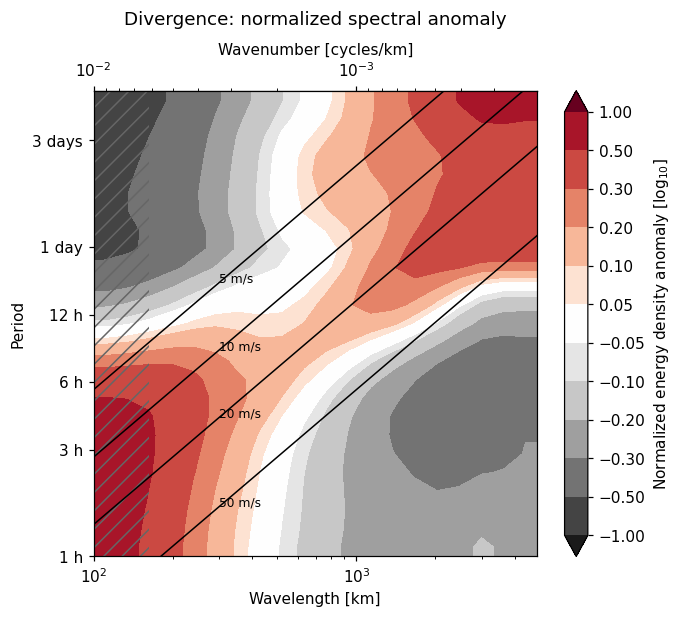

In [12]:
# D (time, lat, lon) with NaN gaps; dx_km, dy_km, dt_hr, PIV_WINDOW_KM from earlier cells
nt, ny, nx = D.shape
nseg = int(15 * 24 / dt_hr)                          # 15-day segments, 50% overlap

# Power spectrum averaged over segments
D_mean = np.nanmean(D, axis=0)                       # time-mean map, so fixed patterns don't leak through gaps
taper = np.hanning(nseg)[:, None, None] * np.outer(np.hanning(ny), np.hanning(nx))
starts = range(0, nt - nseg + 1, nseg // 2)
P = 0
for i in starts:
    d = D[i:i + nseg] - D_mean
    d -= np.nanmean(d, axis=(1, 2), keepdims=True)   # remove each snapshot's spatial mean
    w = taper * np.isfinite(d)                       # taper, zero in gaps
    P = P + np.abs(np.fft.fftn(np.nan_to_num(d) * w))[1:nseg // 2]**2 / np.sum(w**2) / len(starts)

# Bin into log-spaced frequency and |k| bins
f = np.fft.fftfreq(nseg, dt_hr)[1:nseg // 2]                               # cycles/h, positive only
K = np.hypot(np.fft.fftfreq(ny, dy_km)[:, None], np.fft.fftfreq(nx, dx_km))  # cycles/km
f_edges = np.geomspace(1 / 120, 1 / (2 * dt_hr), 26)                       # periods 5 days to 1 h
k_edges = np.geomspace(1 / min(nx * dx_km, ny * dy_km), 1 / 100, 21)       # wavelengths domain size to 100 km
#k_edges = np.geomspace(1 / 1000, 1 / 100, 13)       # 100-1000 km, same as the reference's upper range

fp, kp = np.broadcast_to(f[:, None, None], P.shape).ravel(), np.broadcast_to(K, P.shape).ravel()
E = (np.histogram2d(fp, kp, [f_edges, k_edges], weights=P.ravel())[0]
     / np.histogram2d(fp, kp, [f_edges, k_edges])[0])                      # mean power per bin (NaN = empty bin: use fewer bins)

# Anomaly relative to a background that is separable in f and k: log10(E / (B_f * B_k))
L = gaussian_filter(np.log10(E), 1, mode='nearest')
anom = L - L.mean(axis=0) - L.mean(axis=1)[:, None] + L.mean()


####### PLOTTING ##############
# Plot: bin centres, padded out to the bin edges so the axes run exactly 100 km-domain and 1 h-5 days
lam = np.r_[1 / k_edges[0], 1 / np.sqrt(k_edges[1:] * k_edges[:-1]), 1 / k_edges[-1]]      # [km]
period = np.r_[1 / f_edges[0], 1 / np.sqrt(f_edges[1:] * f_edges[:-1]), 1 / f_edges[-1]]   # [h]
anom = np.pad(anom, 1, mode='edge')
levels = [-1, -0.5, -0.3, -0.2, -0.1, -0.05, 0.05, 0.1, 0.2, 0.3, 0.5, 1]

####### PLOTTING ##############
fig, ax = plt.subplots(figsize=(6.5, 5.5))
cf = ax.contourf(lam, period, anom, levels, cmap='RdGy_r', extend='both',
                 norm=BoundaryNorm(levels, 256, extend='both'))
for c in [5, 10, 20, 50]:                            # phase speed [m/s]: period = wavelength / c
    ax.plot(lam, lam * 1e3 / c / 3600, 'k', lw=1)
    ax.text(300, 300e3 / c / 3600, f'{c} m/s', fontsize=8)
ax.axvspan(lam.min(), PIV_WINDOW_KM, fc='none', ec='0.4', hatch='//', lw=0)   # below PIV window

ax.set(xscale='log', yscale='log', xlim=(lam.min(), lam.max()), ylim=(period.min(), period.max()),
       xlabel='Wavelength [km]', ylabel='Period')
ax.set_yticks([1, 3, 6, 12, 24, 72], ['1 h', '3 h', '6 h', '12 h', '1 day', '3 days'])
ax.set_yticks([], minor=True)
top = ax.secondary_xaxis('top', functions=(lambda x: 1 / x, lambda x: 1 / x))   # wavenumber = 1 / wavelength
top.set_xlabel('Wavenumber [cycles/km]')
ax.set_title('Divergence: normalized spectral anomaly', pad=12)
fig.colorbar(cf, ticks=levels, label='Normalized energy density anomaly [log$_{10}$]')
plt.show()

In [13]:
T = period[np.where(period[:, None] < 48, anom, -np.inf).argmax(axis=0)]   # peak period per wavelength, ignoring > 48 h
df = pd.DataFrame({'wavelength [km]': lam, 'period [h]': T, 'speed [m/s]': lam / T / 3.6})     #divide by 3.6 to get m/s
print(df[(lam > PIV_WINDOW_KM) & (lam < lam.max())].round(1).to_string(index=False))

 wavelength [km]  period [h]  speed [m/s]
          4410.8        23.6         52.0
          3632.3        28.5         35.4
          2991.2        28.5         29.1
          2463.3        23.6         29.0
          2028.5        23.6         23.9
          1670.5        23.6         19.7
          1375.7        19.5         19.6
          1132.9        16.1         19.6
           932.9        13.3         19.5
           768.3        11.0         19.5
           632.7         9.0         19.4
           521.0         7.5         19.4
           429.0         6.2         19.3
           353.3         5.1         19.3
           291.0         5.1         15.9
           239.6         4.2         15.8
           197.3         4.2         13.0
           162.5         3.5         13.0


In [14]:
# Ridge speed in each segment separately; the spread between segments is the error bar.
# Run after the spectrum cell (reuses D, D_mean, taper, starts, nseg, fp, kp, f_edges, k_edges, time).
# Best on the full record (SEG_DAYS = 15 gives 10 segments); a 10-day window gives only 3.

RIDGE_MAX_H = 48                                            # ignore longer periods (synoptic corner)
BAND_KM = (PIV_WINDOW_KM, 300)                              # band for the single error bar: 162-291 km columns

lam_c = 1 / np.sqrt(k_edges[1:] * k_edges[:-1])             # bin centres [km]
per_c = 1 / np.sqrt(f_edges[1:] * f_edges[:-1])             # bin centres [h]

speeds = []                                                 # one row per segment, one column per wavelength
for i in starts:
    d = D[i:i + nseg] - D_mean
    d -= np.nanmean(d, axis=(1, 2), keepdims=True)
    w = taper * np.isfinite(d)
    Pi = np.abs(np.fft.fftn(np.nan_to_num(d) * w))[1:nseg // 2]**2 / np.sum(w**2)
    L = np.log10(np.histogram2d(fp, kp, [f_edges, k_edges], weights=Pi.ravel())[0])
    A = L - L.mean(axis=0) - L.mean(axis=1)[:, None] + L.mean()               # anomaly, no smoothing
    T = per_c[np.where(per_c[:, None] < RIDGE_MAX_H, A, -np.inf).argmax(axis=0)]
    speeds.append(lam_c / T / 3.6)                                            # km/h -> m/s
speeds = np.array(speeds)

# Per wavelength: median and spread across segments
q25, med, q75 = np.percentile(speeds, [25, 50, 75], axis=0)
table = pd.DataFrame({'wavelength [km]': lam_c, 'median [m/s]': med, '25th pct [m/s]': q25, '75th pct [m/s]': q75})
print(table[(lam_c > PIV_WINDOW_KM) & (lam_c < 1500)].round(1).to_string(index=False))

# One speed per segment for the band, then the error bar
band = (lam_c > BAND_KM[0]) & (lam_c < BAND_KM[1])
c_band = np.median(speeds[:, band], axis=1)
print(f'\n{BAND_KM[0]:.0f}-{BAND_KM[1]} km speed by segment start:')
for i, c in zip(starts, c_band):
    print(f'  {str(time[i])[:10]}   {c:5.1f} m/s')
n_indep = max(len(c_band) // 2, 1)                          # segments overlap by half
print(f'mean {c_band.mean():.1f} m/s, std {c_band.std(ddof=1):.1f} m/s, '
      f'standard error {c_band.std(ddof=1) / np.sqrt(n_indep):.1f} m/s (~{n_indep} independent segments)')


/var/folders/96/twpyd53j3j59st06qjb1vj680000gn/T/ipykernel_99472/835570579.py:14: RuntimeWarning: Mean of empty slice
  d -= np.nanmean(d, axis=(1, 2), keepdims=True)


 wavelength [km]  median [m/s]  25th pct [m/s]  75th pct [m/s]
          1375.7          21.7            19.6            23.8
          1132.9          19.6            16.2            22.7
           932.9          19.5            10.8            22.6
           768.3          17.8             8.0            23.6
           632.7          17.7             5.1            22.5
           521.0          19.4            16.8            23.5
           429.0          21.4            19.3            23.4
           353.3          19.3            15.9            23.3
           291.0          19.2            13.8            19.2
           239.6          11.9            10.8            15.8
           197.3          13.0            10.8            13.0
           162.5          13.0            11.3            19.1

162-300 km speed by segment start:
  2023-09-01    11.9 m/s
  2023-09-08    14.4 m/s
  2023-09-16    17.5 m/s
  2023-09-23    11.9 m/s
  2023-10-01    10.8 m/s
  2023-10-09    19.2

## Step 6 — Create Energy Spectrum -- For a 10-DAY SEGMENT



/var/folders/96/twpyd53j3j59st06qjb1vj680000gn/T/ipykernel_99472/521404544.py:13: RuntimeWarning: Mean of empty slice
  X_mean = np.nanmean(X, axis=0)                       # time-mean map, so fixed patterns don't leak through gaps


2023-10-06 to 2023-10-15: 423 time steps, 2 segment(s) of 5 days


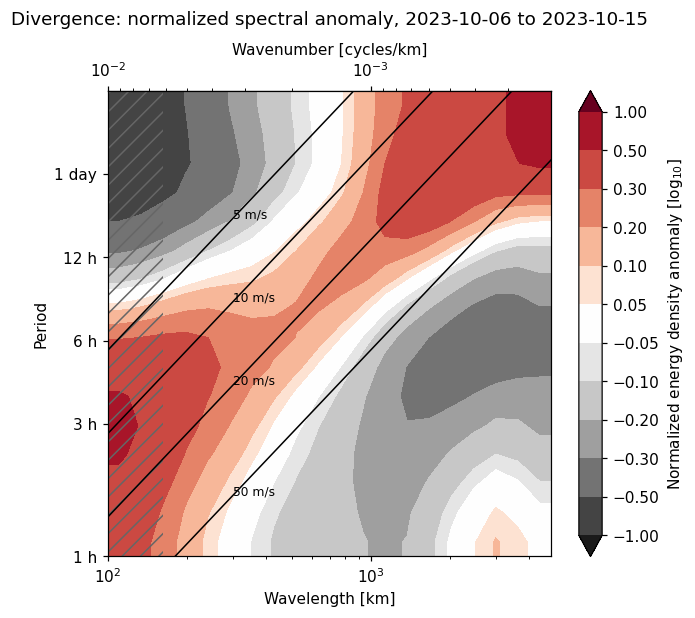

In [15]:
# ---- inputs ------------------------------------------------------------------------------------
START, END   = '2023-10-06', '2023-10-15'   # analysis window, END excluded (full record: '2023-09-01', '2023-12-01')
SEG_DAYS     = 5                             # segment length, 50% overlap (full record: 15)
MAX_PERIOD_H = 48                            # longest period plotted, well below SEG_DAYS * 24 (full record: 120)

# D (time, lat, lon) with NaN gaps; time, dx_km, dy_km, dt_hr, PIV_WINDOW_KM from earlier cells
X = D[(time >= np.datetime64(START)) & (time < np.datetime64(END))]
nt, ny, nx = X.shape
nseg = int(SEG_DAYS * 24 / dt_hr)
assert nt >= nseg, 'window is shorter than one segment: lower SEG_DAYS'

# Power spectrum averaged over segments
X_mean = np.nanmean(X, axis=0)                       # time-mean map, so fixed patterns don't leak through gaps
taper = np.hanning(nseg)[:, None, None] * np.outer(np.hanning(ny), np.hanning(nx))
starts = range(0, nt - nseg + 1, nseg // 2)
P = 0
for i in starts:
    d = X[i:i + nseg] - X_mean
    d -= np.nanmean(d, axis=(1, 2), keepdims=True)   # remove each snapshot's spatial mean
    w = taper * np.isfinite(d)                       # taper, zero in gaps
    P = P + np.abs(np.fft.fftn(np.nan_to_num(d) * w))[1:nseg // 2]**2 / np.sum(w**2) / len(starts)
print(f'{START} to {END}: {nt} time steps, {len(starts)} segment(s) of {SEG_DAYS} days')

# Bin into log-spaced frequency and |k| bins
f = np.fft.fftfreq(nseg, dt_hr)[1:nseg // 2]                               # cycles/h, positive only
K = np.hypot(np.fft.fftfreq(ny, dy_km)[:, None], np.fft.fftfreq(nx, dx_km))  # cycles/km
n_f = max(n for n in range(5, 60)                                         # most period bins with none empty
          if np.histogram(f, np.geomspace(1 / MAX_PERIOD_H, 1 / (2 * dt_hr), n + 1))[0].min() > 0)
f_edges = np.geomspace(1 / MAX_PERIOD_H, 1 / (2 * dt_hr), n_f + 1)         # periods MAX_PERIOD_H to 1 h
k_edges = np.geomspace(1 / min(nx * dx_km, ny * dy_km), 1 / 100, 21)       # wavelengths domain size to 100 km

fp, kp = np.broadcast_to(f[:, None, None], P.shape).ravel(), np.broadcast_to(K, P.shape).ravel()
E = (np.histogram2d(fp, kp, [f_edges, k_edges], weights=P.ravel())[0]
     / np.histogram2d(fp, kp, [f_edges, k_edges])[0])                      # mean power per bin (NaN = empty bin: use fewer bins)

# Anomaly relative to a background that is separable in f and k: log10(E / (B_f * B_k))
L = gaussian_filter(np.log10(E), 1, mode='nearest')
anom = L - L.mean(axis=0) - L.mean(axis=1)[:, None] + L.mean()

# Plot: bin centres, padded out to the bin edges so the axes run exactly 100 km-domain and 1 h-MAX_PERIOD_H
lam = np.r_[1 / k_edges[0], 1 / np.sqrt(k_edges[1:] * k_edges[:-1]), 1 / k_edges[-1]]      # [km]
period = np.r_[1 / f_edges[0], 1 / np.sqrt(f_edges[1:] * f_edges[:-1]), 1 / f_edges[-1]]   # [h]
anom = np.pad(anom, 1, mode='edge')
levels = [-1, -0.5, -0.3, -0.2, -0.1, -0.05, 0.05, 0.1, 0.2, 0.3, 0.5, 1]

fig, ax = plt.subplots(figsize=(6.5, 5.5))
cf = ax.contourf(lam, period, anom, levels, cmap='RdGy_r', extend='both',
                 norm=BoundaryNorm(levels, 256, extend='both'))
for c in [5, 10, 20, 50]:                            # phase speed [m/s]: period = wavelength / c
    ax.plot(lam, lam * 1e3 / c / 3600, 'k', lw=1)
    ax.text(300, 300e3 / c / 3600, f'{c} m/s', fontsize=8)
ax.axvspan(lam.min(), PIV_WINDOW_KM, fc='none', ec='0.4', hatch='//', lw=0)   # below PIV window

ax.set(xscale='log', yscale='log', xlim=(lam.min(), lam.max()), xlabel='Wavelength [km]', ylabel='Period')
ax.set_yticks([1, 3, 6, 12, 24, 72], ['1 h', '3 h', '6 h', '12 h', '1 day', '3 days'])
ax.set_yticks([], minor=True)
ax.set_ylim(period.min(), period.max())             # after the ticks, so ticks beyond MAX_PERIOD_H don't stretch the axis
top = ax.secondary_xaxis('top', functions=(lambda x: 1 / x, lambda x: 1 / x))   # wavenumber = 1 / wavelength
top.set_xlabel('Wavenumber [cycles/km]')
ax.set_title(f'Divergence: normalized spectral anomaly, {START} to {END}', pad=12)
fig.colorbar(cf, ticks=levels, label='Normalized energy density anomaly [log$_{10}$]')
plt.show()

In [16]:
T = period[np.where(period[:, None] < 48, anom, -np.inf).argmax(axis=0)]   # peak period per wavelength, ignoring > 48 h
df = pd.DataFrame({'wavelength [km]': lam, 'period [h]': T, 'speed [m/s]': lam / T / 3.6})     #divide by 3.6 to get m/s
print(df[(lam > PIV_WINDOW_KM) & (lam < lam.max())].round(1).to_string(index=False))

 wavelength [km]  period [h]  speed [m/s]
          4410.8        42.5         28.8
          3632.3        42.5         23.7
          2991.2        33.4         24.9
          2463.3        26.2         26.1
          2028.5        26.2         21.5
          1670.5        20.6         22.5
          1375.7        20.6         18.6
          1132.9        20.6         15.3
           932.9        12.7         20.4
           768.3        10.0         21.4
           632.7        10.0         17.6
           521.0         7.8         18.5
           429.0         6.1         19.4
           353.3         6.1         16.0
           291.0         4.8         16.8
           239.6         4.8         13.8
           197.3         4.8         11.4
           162.5         3.8         11.9


## Step 7 — Synthetic Waves With Known Speed Injection Test (very AI CODED ** proceed with caution)
Injection test: synthetic waves with known speeds, sampled through your real cloud gaps and run
through the same spectrum steps. If the ridge speeds come back as the input speeds, the method
(gaps, tapers, bins, smoothing) is not what produces the 13-16 m/s result at 162-291 km.
Run after the spectrum cell. Uses: D, dx_km, dy_km, dt_hr, f_edges, k_edges, PIV_WINDOW_KM


In [ ]:
SPEED_LONG  = 20          # m/s above 330 km (matches your ridge there)
TEST_SPEEDS = [14, 25]    # m/s below 330 km: 14 = your result, 25 = control
NOISE       = 1.0         # white-noise variance relative to total wave variance
U, V        = 0.0, 0.0    # set to 4, -6 to Doppler-shift the waves by your mean wind

nt, ny, nx = D.shape
mask = np.isfinite(D)
x = np.arange(nx, dtype=np.float32) * dx_km * 1e3
y = np.arange(ny, dtype=np.float32) * dy_km * 1e3
t = np.arange(nt) * dt_hr * 3600


def synthetic(c_short, n_waves=150, seed=0):
    rng = np.random.default_rng(seed)
    S = np.zeros((nt, ny, nx), np.float32)
    for lam in np.geomspace(120e3, 4500e3, n_waves):                        # wavelength [m]
        c = SPEED_LONG if lam > 330e3 else c_short
        k, th = 2 * np.pi / lam, rng.uniform(0, 2 * np.pi)                    # random direction
        phase = k * (np.cos(th) * x[None, :] + np.sin(th) * y[:, None]) + rng.uniform(0, 2 * np.pi)
        wt = (k * (c + np.cos(th) * U + np.sin(th) * V) * t).astype(np.float32)   # omega * t
        S += np.cos(wt)[:, None, None] * np.cos(phase)                        # cos(phase - omega t)
        S += np.sin(wt)[:, None, None] * np.sin(phase)
    S += rng.normal(0, np.sqrt(NOISE * n_waves / 2), S.shape).astype(np.float32)
    S[~mask] = np.nan
    return S


def spectrum(field):                        # same steps as the spectrum cell
    nseg = int(15 * 24 / dt_hr)
    fmean = np.nanmean(field, axis=0)
    taper = np.hanning(nseg)[:, None, None] * np.outer(np.hanning(ny), np.hanning(nx))
    P = 0
    for i in range(0, nt - nseg + 1, nseg // 2):
        d = field[i:i + nseg] - fmean
        d -= np.nanmean(d, axis=(1, 2), keepdims=True)
        w = taper * np.isfinite(d)
        P = P + np.abs(np.fft.fftn(np.nan_to_num(d) * w))[1:nseg // 2]**2 / np.sum(w**2)
    f = np.fft.fftfreq(nseg, dt_hr)[1:nseg // 2]
    K = np.hypot(np.fft.fftfreq(ny, dy_km)[:, None], np.fft.fftfreq(nx, dx_km))
    fp, kp = np.broadcast_to(f[:, None, None], P.shape).ravel(), np.broadcast_to(K, P.shape).ravel()
    return np.histogram2d(fp, kp, [f_edges, k_edges], weights=P.ravel())[0]


def ridge_speed(E, smooth):                 # same anomaly and ridge steps as before
    L = gaussian_filter(np.log10(E), smooth, mode='nearest')
    A = L - L.mean(axis=0) - L.mean(axis=1)[:, None] + L.mean()
    period = 1 / np.sqrt(f_edges[1:] * f_edges[:-1])
    sel = period < 48
    return lam_c * 1e3 / (period[sel][A[sel].argmax(axis=0)] * 3600)


lam_c = 1 / np.sqrt(k_edges[1:] * k_edges[:-1])
E = spectrum(D)
results = {'real s1': ridge_speed(E, 1), 'real s0': ridge_speed(E, 0)}
for c in TEST_SPEEDS:
    E = spectrum(synthetic(c))
    results[f'in{c} s1'] = ridge_speed(E, 1)
    results[f'in{c} s0'] = ridge_speed(E, 0)

# speeds [m/s] per wavelength; s1 = smoothing on, s0 = off; inXX = injected speed below 330 km
print('lambda_km' + ''.join(f'{name:>10}' for name in results))
for j in np.where((lam_c > PIV_WINDOW_KM) & (lam_c < 1500))[0]:
    print(f'{lam_c[j]:9.0f}' + ''.join(f'{r[j]:10.1f}' for r in results.values()))

/var/folders/96/twpyd53j3j59st06qjb1vj680000gn/T/ipykernel_99472/1652792392.py:30: RuntimeWarning: Mean of empty slice
  fmean = np.nanmean(field, axis=0)
/var/folders/96/twpyd53j3j59st06qjb1vj680000gn/T/ipykernel_99472/1652792392.py:35: RuntimeWarning: Mean of empty slice
  d -= np.nanmean(d, axis=(1, 2), keepdims=True)
